# Adult Income Classification — Neural Network from Scratch

A reproducible experiment that builds a fully connected classifier with JAX and compares RMSProp, AdaGrad, and SGD with momentum on the UCI Adult dataset. The saved run reports 85.38% test accuracy for the best RMSProp model.

## ANN Classifier for the UCI "Adult" Dataset

This notebook trains and evaluates an **Artificial Neural Network (ANN)** classifier on the **UCI Adult dataset**, performing model selection and generating diagnostic visualizations.


---

##  About the ANN Classifier

Artificial Neural Networks (ANNs) are built from layers of interconnected “neurons,” where each neuron computes a weighted sum of its inputs, applies a nonlinear activation (like ReLU or sigmoid), and passes the result forward. By stacking multiple hidden layers, ANNs learn hierarchical feature representations, making them flexible function approximators. They’re especially useful when the relationship between inputs and outputs is complex or high-dimensional—tasks like image recognition, speech understanding, or any scenario where handcrafted rules struggle. Training happens by minimizing a loss function with gradient-based optimization (e.g., backpropagation), enabling the network to adapt its weights to capture intricate patterns in data.












In [1]:
# -------------------------
# 0) Import libraries
# -------------------------

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (
    train_test_split, GridSearchCV, StratifiedKFold, learning_curve
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay,
    ConfusionMatrixDisplay, average_precision_score
)
import joblib

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['grid.alpha'] = 0.3

## Data loading & exploration

We load the Adult dataset. If you already have a local CSV, set `data_path`. Otherwise the notebook tries the common UCI URL.

In [2]:
# -------------------------
# 1) Data load & data preparation
# -------------------------

data_path = None
uci_data_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

column_names = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]

def load_adult(data_path=None):
    if data_path and os.path.exists(data_path):
        try:
            df = pd.read_csv(data_path, header=None, names=column_names, sep=r",\s*", engine="python")
        except Exception:
            df = pd.read_csv(data_path, header=None, names=column_names)
    else:
        print("Downloading Adult dataset from UCI (adult.data)...")
        df = pd.read_csv(uci_data_url, header=None, names=column_names, sep=r",\s*", engine="python")
    # strip strings, replace '?' with NaN, clean income trailing dots
    df = df.map(lambda x: x.strip() if isinstance(x, str) else x)
    df = df.replace('?', np.nan)
    df['income'] = df['income'].str.replace(r'\.', '', regex=True).str.strip()
    return df

df = load_adult(data_path)
print("Loaded dataset shape:", df.shape)
print(df.head())

Loaded dataset shape: (32561, 15)
   age         workclass  fnlwgt  education  education-num  \
0   39         State-gov   77516  Bachelors             13   
1   50  Self-emp-not-inc   83311  Bachelors             13   
2   38           Private  215646    HS-grad              9   
3   53           Private  234721       11th              7   
4   28           Private  338409  Bachelors             13   

       marital-status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Black    Male   
4  Married-civ-spouse     Prof-specialty           Wife  Black  Female   

   capital-gain  capital-loss  hours-per-week native-country income  
0          2174             0              40  United-States  <=50K  
1       

## Prepare features and split

- We'll separate numeric and categorical features.
- Use `train_test_split` with stratification by the target to keep class balance.

In [3]:
# -------------------------
# 2) Prepare X, y and do holdout split
# -------------------------

X = df.drop(columns=['income'])
y = df['income'].replace({'<=50K': 0, '>50K': 1, '<=50K.': 0, '>50K.': 1}).astype(int)

# Reserve 20% for final testing (empirical error)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Train shape: (26048, 14) Test shape: (6513, 14)


## Preprocessing pipeline

We create a `ColumnTransformer`:
- Standard scale numeric features (`StandardScaler`)
- One-hot encode categorical features (`OneHotEncoder`, handle unknown categories at transform time)

In [4]:
# -------------------------
# 3) Preprocessing pipelines
# -------------------------
# Detect numeric and categorical columns

numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object']).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
], remainder='drop')

Numeric features: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical features: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


Apply preprocessing to train/test splits

In [5]:
# Fit preprocessor on training data
preprocessor.fit(X_train)

X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)


Separate  the Valid set

In [6]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_processed, y_train, test_size=0.1, random_state=42, stratify=y_train
)

X_test = X_test_processed

In [7]:
print("Preprocessing complete.")
# -------------------------
print("Train: ", X_train.shape, y_train.shape)
print("Valid:  ", X_valid.shape, y_valid.shape)
print("Test:  ", X_test.shape, y_test.shape)


Preprocessing complete.
Train:  (23443, 105) (23443,)
Valid:   (2605, 105) (2605,)
Test:   (6513, 105) (6513,)


About Labels for training

In [8]:
pd.DataFrame(y_train).head()

,income
25076,0
20140,1
19771,0
28004,0
10710,0


In [9]:
pd.DataFrame(y_train).describe()

,income
count,23443.000000
mean,0.240839
std,0.427602
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,1.000000


In [10]:
pd.DataFrame(y_train).info()

<class 'pandas.core.frame.DataFrame'>
Index: 23443 entries, 25076 to 11849
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   income  23443 non-null  int64
dtypes: int64(1)
memory usage: 366.3 KB


In [11]:
pd.DataFrame(y_train).value_counts()

income
0         17797
1          5646
Name: count, dtype: int64

The target is imbalanced: roughly 24% of the training examples belong to the `>50K` class. Accuracy must therefore be interpreted together with class-specific precision and recall. Resampling methods such as SMOTE are possible follow-up experiments, but are not applied in this saved run.

## ANN architecture construction

In this section, we develop a fully supervised Artificial Neural Network (ANN) to predict whether an individual's income exceeds $50K from tabular census features. The model receives preprocessed census features and learns to map them to the two income classes through iterative optimization. To train the ANN efficiently, we experiment with several optimization algorithms—RMSProp, SGD with Momentum, and AdaGrad—each offering different strategies for adjusting the learning rate and navigating the loss landscape. By comparing their behavior during training and validation, we can assess how each optimizer influences convergence speed, stability, and final predictive performance. This provides valuable insight into how optimization choices affect the overall effectiveness of the ANN for income classification.

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import jax.numpy as jnp
import jax
import time

Define the initialization of the parameters and the ANN's structure

In [13]:
#Parameters's Initialization with the Glorot-Xavier Method
def initialize_params(layers_size):
    np.random.seed(0)  # for reproducibility
    params = list()
    
    for i in range(len(layers_size) - 1):
        W = np.random.randn(layers_size[i + 1], layers_size[i]) * np.sqrt(
            2 / (layers_size[i + 1] + layers_size[i])
        )
        b = np.zeros((layers_size[i + 1], 1))
        params.append(W)
        params.append(b)
    
    return params


#Building the ANN Model
def ANN(x, params):

    activation = jax.nn.tanh
    
    layer = x
    num_layers = int(len(params) / 2 + 1)
    weights = params[0::2]
    biases = params[1::2]
    
    for i in range(num_layers - 1):
        layer = jnp.dot(weights[i], layer) - biases[i]
        if i < num_layers - 2:
            layer = activation(layer)

    layer = jax.nn.softmax(layer, axis=0)
    return layer

Define the Loss Functions and the Accuracy Function

In [14]:
# Computes the Mean Squared Error (MSE) loss between predicted and actual values
def MSE(x, y, params): 
    return jnp.mean( ( ANN( x, params ) - y ) ** 2 ) 

# Computes the Cross-Entropy loss between predicted and actual values
def cross_entropy(x, y, params):
 return -jnp.mean( jnp.sum( y * jnp.log( ANN( x, params ) ), axis=0 ))  

# Function to compute the accuracy of the model
def accuracy(x, y, params):
    return jnp.mean( jnp.argmax( ANN( x, params ), axis=0 ) == jnp.argmax( y, axis=0 ))

Grid Search Optimize for the best hyper parameters with RMSProp algorithm (I am not going to repeat the grid search for other algorithms, because it's pretty computationale expensive):
in order to find the best hyper parameters I have performed nested loops trying the optimization of the loss functions with different parameters.
In each iteration I compared the new accuracy on the validation set with the best accuracy found so far.

Actually I have performed many grid search trying many different hyperparameters. Here below I have reported just some of them that I have tested.

In [ ]:
n_train = X_train.shape[0]
n_features = X_train_processed.shape[1]
num_labels = 2  # Binary classification: <=50K and >50K

In [17]:
# 1) Dense invece di sparse
X_train = X_train.toarray() if hasattr(X_train, "toarray") else X_train
X_valid = X_valid.toarray() if hasattr(X_valid, "toarray") else X_valid
X_test  = X_test.toarray()  if hasattr(X_test, "toarray")  else X_test

# 2) One-hot encoding delle etichette
num_labels = 2
y_train = np.array(jax.nn.one_hot(y_train, num_labels))
y_valid = np.array(jax.nn.one_hot(y_valid, num_labels))
y_test  = np.array(jax.nn.one_hot(y_test, num_labels))

# 3) n_train coerente con X_train usato sotto
n_train = X_train.shape[0]

In [38]:
#Lists of different hyperparameters to test
layers_sizes = [[X_train.shape[1], 256,512,256, 2], [X_train.shape[1], 128,128,128, 2], [X_train.shape[1], 256,256,256, 2]]
nums_epochs = [50, 100]
batch_sizes = [64, 128]
learning_rates = [1e-2, 3.67e-3, 1e-1]
decay_rates = [0.9, 0.95, 0.99]
deltas = [1e-7, 1e-5, 1e-3]

#Initialization of the best parameters and accuracy
best_parameters = [layers_sizes[0], nums_epochs[0], batch_sizes[0], learning_rates[0], decay_rates[0], deltas[0]]
best_accuracy = 0.0

#Grid Search for the best hyperparameters
for layers_size in layers_sizes:
  for num_epochs in nums_epochs:
    for batch_size in batch_sizes:
      for learning_rate in learning_rates:
        for decay_rate in decay_rates:
          for delta in deltas:
            
            #Initialization of the parameters
            params = initialize_params(layers_size)
            
            #Jitting the functions
            grad_jit = jax.jit(jax.grad(cross_entropy, argnums=2))
            accuracy_jit = jax.jit(accuracy)
            
            #Initialization of the cumulated squared gradients
            cumulated_sqr_grad = [0.0 for i in range(len(params))]
              
            #Update Rule (RMSProp)
            for epoch in range(num_epochs):
              
              idxs = np.random.choice(n_train, batch_size)
              x_batch = X_train[idxs, :].T   # (n_features, batch_size)
              y_batch = y_train[idxs, :].T   # (num_labels, batch_size)

              grads = grad_jit(x_batch, y_batch, params)

              for i in range(len(params)):

                cumulated_sqr_grad[i] = (decay_rate * cumulated_sqr_grad[i] + (1- decay_rate) * grads[i] * grads[i])

                params[i] -=  ( learning_rate / (jnp.sqrt(cumulated_sqr_grad[i]) + delta) * grads[i])
            
            #Computing the accuracy on the validation set with the updated parameters
            acc_rann = accuracy_jit(X_valid.T, y_valid.T, params)
            
            #Updating the best accuracy and parameters
            if acc_rann > best_accuracy:
              best_accuracy = acc_rann
              best_parameters = [layers_size, num_epochs, batch_size, learning_rate, decay_rate, delta]


#Print the best accuracy and the best parameters
print(f"Best Accuracy: {best_accuracy}")

print("\n\n\n")
print("Best Parameters:")
print("Layers Size:", best_parameters[0])
print("Number of Epochs:", best_parameters[1])
print("Batch Size:", best_parameters[2])
print("Learning Rate:", best_parameters[3])
print("Decay Rate:", best_parameters[4])
print("Delta:", best_parameters[5])

Best Accuracy: 0.8468330502510071




Best Parameters:
Layers Size: [105, 256, 512, 256, 2]
Number of Epochs: 100
Batch Size: 128
Learning Rate: 0.00367
Decay Rate: 0.95
Delta: 1e-07


## OPTIMIZATIONS' COMPARISON

In the next cells I am going to compare the optimization of the parameters of the ANN done by different algorithms (RMSProp, ADAGRAD, SGD with Momentum, SGD and Gradient Descent). The comparison is made by using the best paramters obtained in the GridSearch with the RMSProp and the number of epochs equal to 2000 in order to let every descent to converge. Some algorithms require more parameters than the best parameters obtained before and those are initialize in the proper cells.

## RMSProp

Optimization with the best hyperparameters and plot the history

Validation accuracy: 84.683304%
Validation accuracy: 84.683304%


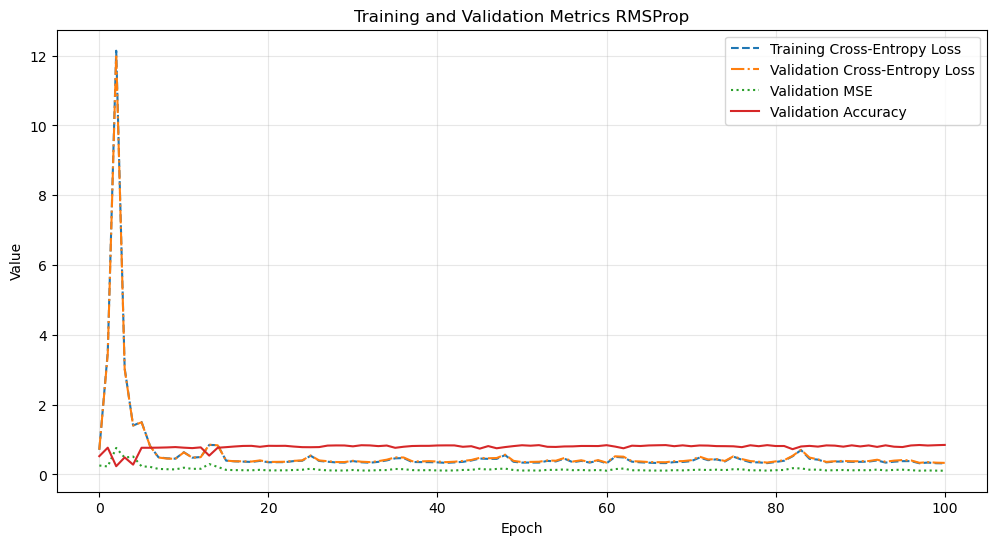

In [39]:
#Unpacking the best parameters' list
layers_size, num_epochs, batch_size, learning_rate, decay_rate, delta = best_parameters

#Initialization of the parameters
params = initialize_params(layers_size)

#Jitting the functions
grad = jax.jit(jax.grad(cross_entropy, argnums=2))
cross_entropy_jit = jax.jit(cross_entropy)
grad_jit = jax.jit(grad)
MSE_jit = jax.jit(MSE)
accuracy_jit = jax.jit(accuracy)

#Initialization of the history lists
history_train_Xen_RMS = list()
history_valid_Xen_RMS = list()
history_valid_MSE_RMS = list()
history_valid_acc_RMS = list()

#Dump the initial metrics
def dump():
    # X_: (N, d) -> (d, N)  |  y_: (N, C) -> (C, N)
    history_train_Xen_RMS.append(cross_entropy_jit(X_train.T, y_train.T, params))
    history_valid_Xen_RMS.append(cross_entropy_jit(X_valid.T, y_valid.T, params))
    history_valid_MSE_RMS.append(MSE_jit(X_valid.T, y_valid.T, params))
    history_valid_acc_RMS.append(accuracy_jit(X_valid.T, y_valid.T, params))

dump()

#Initialization of the cumulated squared gradients
cumulated_sqr_grad = [0.0 for _ in range(len(params))]

#Training the model (RMSProp)
for epoch in range(num_epochs):

    idxs = np.random.choice(n_train, batch_size)
    x_batch = X_train[idxs, :].T   # (n_features, batch_size)
    y_batch = y_train[idxs, :].T   # (num_labels, batch_size)

    grads = grad_jit(x_batch, y_batch, params)

    for i in range(len(params)):
        cumulated_sqr_grad[i] = decay_rate * cumulated_sqr_grad[i] + (1 - decay_rate) * grads[i] * grads[i]
        params[i] = params[i] - learning_rate * grads[i] / (jnp.sqrt(cumulated_sqr_grad[i]) + delta)
    dump()

# Validation Accuracy
acc = accuracy_jit(X_valid.T, y_valid.T, params)
print("Validation accuracy: %f%%" % (100 * acc))
print("Validation accuracy: %f%%" % (100 * acc))

# Plot the metrics and the history of the training
plt.figure(figsize=(12, 6))

plt.plot(history_train_Xen_RMS, label='Training Cross-Entropy Loss', linestyle='--')
plt.plot(history_valid_Xen_RMS, label='Validation Cross-Entropy Loss', linestyle='-.')
plt.plot(history_valid_MSE_RMS, label='Validation MSE', linestyle=':')
plt.plot(history_valid_acc_RMS, label='Validation Accuracy', linestyle='-')

# Labels and Title
plt.xlabel('Epoch')
plt.ylabel('Value')
plt.title('Training and Validation Metrics RMSProp')
plt.legend()
plt.grid(True)

# Show the plot
plt.show()

Test the ANN best optimized on the test dataset

In [40]:
acc = accuracy(X_test.T, y_test.T, params)
print("Accuracy Test Set with RMSProp: %f%%" % (100 * acc))

Accuracy Test Set with RMSProp: 85.383080%


## ADAGRAD

Validation accuracy: 84.030708%


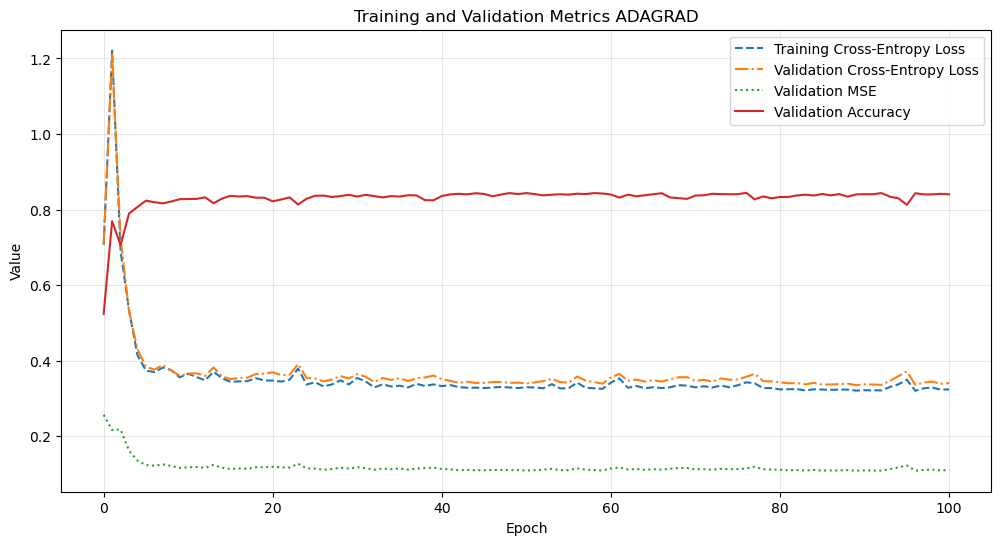

In [41]:
#Unpacking the best parameters' list
layers_size, num_epochs, batch_size, learning_rate, decay_rate, delta = best_parameters

#Initialization of the parameters
params = initialize_params(layers_size)

#Jitting the functions
grad = jax.jit(jax.grad(cross_entropy, argnums=2))
cross_entropy_jit = jax.jit(cross_entropy)
grad_jit = jax.jit(grad)
MSE_jit = jax.jit(MSE)
accuracy_jit = jax.jit(accuracy)

#Initialization of the history lists
history_train_Xen_ADAGRAD = list()
history_valid_Xen_ADAGRAD = list()
history_valid_MSE_ADAGRAD = list()
history_valid_acc_ADAGRAD = list()

#Dump the initial metrics
def dump():
    # X_: (N, d) -> (d, N)  |  y_: (N, C) -> (C, N)
    history_train_Xen_ADAGRAD.append(cross_entropy_jit(X_train.T, y_train.T, params))
    history_valid_Xen_ADAGRAD.append(cross_entropy_jit(X_valid.T, y_valid.T, params))
    history_valid_MSE_ADAGRAD.append(MSE_jit(X_valid.T, y_valid.T, params))
    history_valid_acc_ADAGRAD.append(accuracy_jit(X_valid.T, y_valid.T, params))

dump()

#Initialization of the cumulated squared gradients
cumulated_square_grad = [0.0 for _ in range(len(params))]

#Training the model (Adagrad)
for epoch in range(num_epochs):
    
    idxs = np.random.choice(n_train, batch_size)
    x_batch = X_train[idxs, :].T   # (n_features, batch_size)
    y_batch = y_train[idxs, :].T   # (num_labels, batch_size)

    grads = grad_jit(x_batch, y_batch, params)
    for i in range(len(params)):
        cumulated_square_grad[i] += grads[i] * grads[i]
        params[i] -= (
            learning_rate / (delta + jnp.sqrt(cumulated_square_grad[i])) * grads[i]
        )
    dump()

# Validation Accuracy
acc = accuracy(X_valid.T, y_valid.T, params)
print("Validation accuracy: %f%%" % (100 * acc))

# Plot the metrics and the history of the training
plt.figure(figsize=(12, 6))

plt.plot(history_train_Xen_ADAGRAD, label='Training Cross-Entropy Loss', linestyle='--')
plt.plot(history_valid_Xen_ADAGRAD, label='Validation Cross-Entropy Loss', linestyle='-.')
plt.plot(history_valid_MSE_ADAGRAD, label='Validation MSE', linestyle=':')
plt.plot(history_valid_acc_ADAGRAD, label='Validation Accuracy', linestyle='-')

# Labels and Title
plt.xlabel('Epoch')
plt.ylabel('Value')
plt.title('Training and Validation Metrics ADAGRAD')
plt.legend()
plt.grid(True)

# Show the plot
plt.show()

Test the ANN ADAGRAD's optimized on the test dataset

In [42]:
acc = accuracy(X_test.T, y_test.T, params)
print("Accuracy Test Set with ADAGRAD: %f%%" % (100 * acc))

Accuracy Test Set with ADAGRAD: 85.152771%


## SGD with MOMENTUM

Validation accuracy: 83.608452%


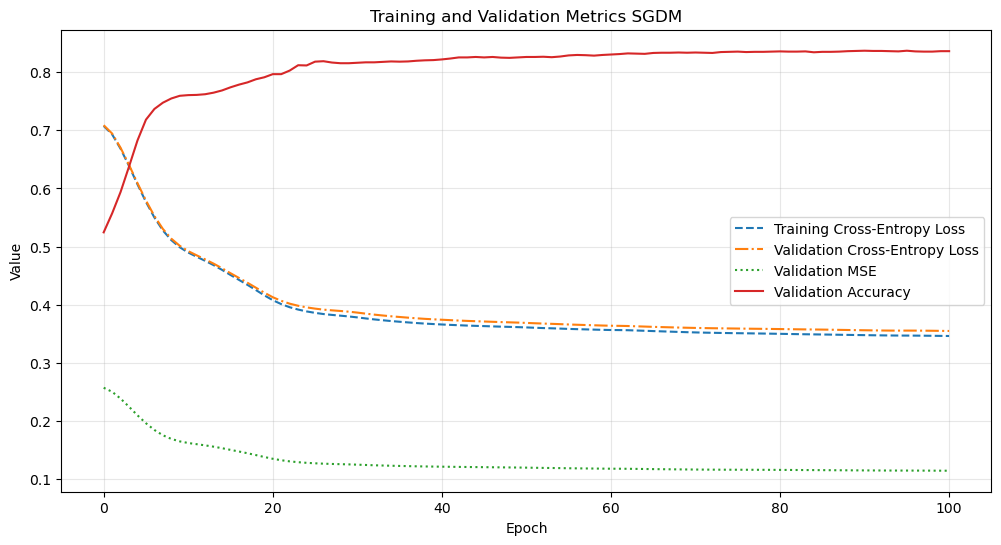

In [48]:
# --- SGD with Momentum Hyperparameters ---
learning_rate_max = 3e-3      
learning_rate_min = 1e-4
alpha = 0.9
learning_rate_decay = 200      # decay within training window
clip_value = 1.0               # gradient clipping

# --- Reinitialize parameters ---
params = initialize_params(layers_size)

# --- Velocity ---
velocity = [jnp.zeros_like(p) for p in params]

def lr_schedule(epoch):
    return max(
        learning_rate_min,
        learning_rate_max * (1 - epoch / learning_rate_decay)
    )

history_train_Xen_SGDM = []
history_valid_Xen_SGDM = []
history_valid_MSE_SGDM = []
history_valid_acc_SGDM = []

def dump():
    history_train_Xen_SGDM.append(cross_entropy_jit(X_train.T, y_train.T, params))
    history_valid_Xen_SGDM.append(cross_entropy_jit(X_valid.T, y_valid.T, params))
    history_valid_MSE_SGDM.append(MSE_jit(X_valid.T, y_valid.T, params))
    history_valid_acc_SGDM.append(accuracy_jit(X_valid.T, y_valid.T, params))

dump()

# --- TRAINING LOOP ---
for epoch in range(num_epochs):

    eta = lr_schedule(epoch)

    idxs = np.random.choice(n_train, batch_size)
    x_batch = X_train[idxs, :].T
    y_batch = y_train[idxs, :].T

    # *** IMPORTANT: recompute gradients ***
    grads = grad_jit(x_batch, y_batch, params)

    # Gradient clipping
    grads = [jnp.clip(g, -clip_value, clip_value) for g in grads]

    # SGD+Momentum update
    new_params = []
    new_velocity = []

    for p, g, v in zip(params, grads, velocity):
        v_new = alpha * v - eta * g
        p_new = p + v_new

        new_velocity.append(v_new)
        new_params.append(p_new)

    params = new_params
    velocity = new_velocity

    dump()


# Validation Accuracy
acc = accuracy(X_valid.T, y_valid.T, params)
print("Validation accuracy: %f%%" % (100 * acc))

# Plot the metrics and the history of the training
plt.figure(figsize=(12, 6))

plt.plot(history_train_Xen_SGDM, label='Training Cross-Entropy Loss', linestyle='--')
plt.plot(history_valid_Xen_SGDM, label='Validation Cross-Entropy Loss', linestyle='-.')
plt.plot(history_valid_MSE_SGDM, label='Validation MSE', linestyle=':')
plt.plot(history_valid_acc_SGDM, label='Validation Accuracy', linestyle='-')

# Labels and Title
plt.xlabel('Epoch')
plt.ylabel('Value')
plt.title('Training and Validation Metrics SGDM')
plt.legend()
plt.grid(True)

# Show the plot
plt.show()

Test the ANN SGD with Momentum's optimized on the test dataset

In [49]:
acc = accuracy(X_test.T, y_test.T, params)
print("Accuracy Test Set with SGD with Momentum: %f%%" % (100 * acc))

Accuracy Test Set with SGD with Momentum: 84.369728%


## COMMENT ABOUT THE RESULTS OBTAINED BY THE OPTIMIZATION'S ALGORITHM

## Overall Comparison Plot

Training Cross-Entropy Loss Evolution for different optimization's algorithms

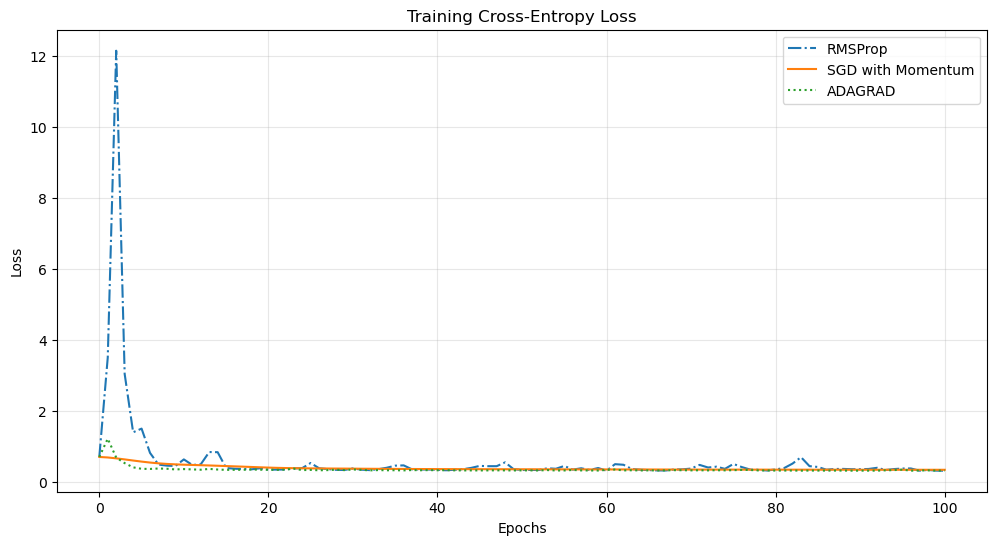

In [50]:
plt.figure(figsize=(12, 6))


plt.plot(history_train_Xen_RMS, label='RMSProp', linestyle='-.')
plt.plot(history_train_Xen_SGDM, label='SGD with Momentum', linestyle='-')
plt.plot(history_train_Xen_ADAGRAD, label='ADAGRAD', linestyle='dotted')


plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Cross-Entropy Loss')
plt.legend()
plt.grid(True)

plt.show()

Validation Cross-Entropy Loss Evolution for different optimization's algorithms

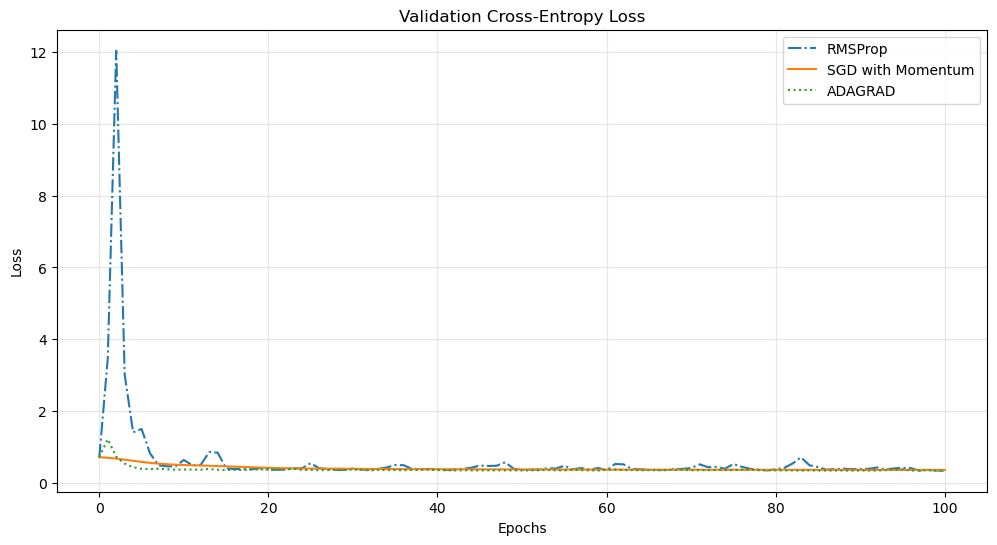

In [51]:
plt.figure(figsize=(12, 6))



plt.plot(history_valid_Xen_RMS, label='RMSProp', linestyle='-.')
plt.plot(history_valid_Xen_SGDM, label='SGD with Momentum', linestyle='-')
plt.plot(history_valid_Xen_ADAGRAD, label='ADAGRAD', linestyle='dotted')


plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Validation Cross-Entropy Loss')
plt.legend()
plt.grid(True)

plt.show()

Validation Accuracy Evolution for different optimization's algorithms

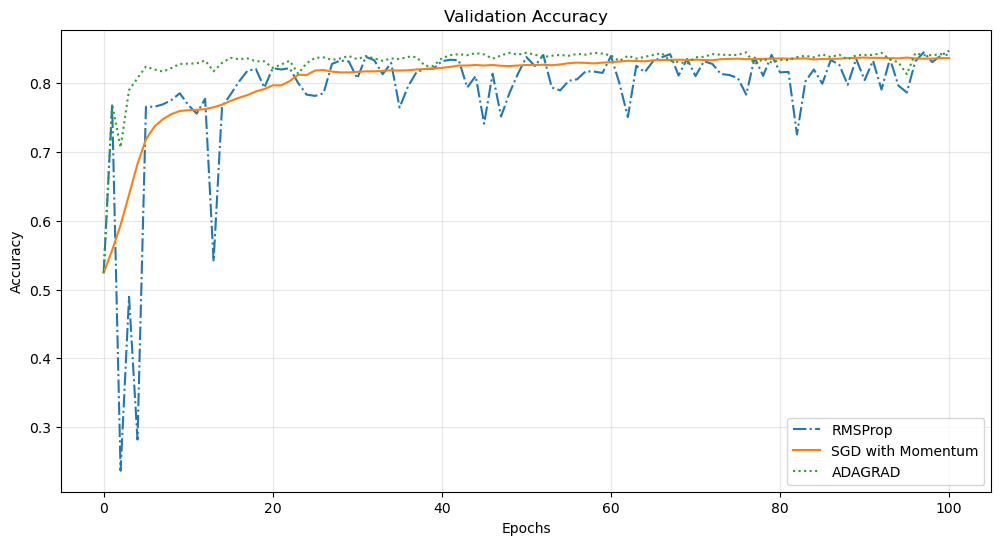

In [52]:
plt.figure(figsize=(12, 6))



plt.plot(history_valid_acc_RMS, label='RMSProp', linestyle='-.')
plt.plot(history_valid_acc_SGDM, label='SGD with Momentum', linestyle='-')
plt.plot(history_valid_acc_ADAGRAD, label='ADAGRAD', linestyle='dotted')


plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Validation Accuracy')
plt.legend()
plt.grid(True)

plt.show()

## Final Considerations on RMSProp, SGD with Momentum, and AdaGrad

The saved runs produce similar holdout results: **RMSProp reaches 85.38% test accuracy**, AdaGrad reaches **85.15%**, and SGD with Momentum reaches **84.37%**. RMSProp therefore has the strongest test result in this experiment, while the learning curves show different convergence and stability profiles. Because the gaps are small and come from a single train/test split, they should not be interpreted as a universal ranking of the optimizers. Repeated runs or nested cross-validation would be needed for a stronger comparison.